# Level 1 walkthrough: predicting the image's noise parameters from the traces

**Level 1 question:** can σe (read noise), λ (dark charge) and the gain of an image be predicted from an amplifier's traces?
Packets are taken **by hand**, processed, and every model is trained and tested **offline**. Nothing here talks to the hardware.

| Step | Tool | Section |
|---|---|---|
| take a packet by hand | `daq_scripts/manual_packet.sh` | 1 |
| find its files, read its settings | `src/make_manual_manifest.py` | 2 |
| traces → features and curves; image → labels, λ row by row | `src/process_packet.py`, `src/image_rows.py` | 3, 4 |
| one ready-to-train file per model family | `src/ml/real_inputs.py` (called by `process_packet.py`) | 3 |
| train and test every model, report | `lvl1/train_lvl1.py` | 5, 6 |

Two rules hold throughout:
* **No amplifier labels.** No model is told which amplifier it sees; it sees that amplifier's own traces. Board and channel are used only to score.
* **One trace → one example.** A packet read by 4 amplifiers gives 4 examples (100 packets = 400). A packet's 4 examples always stay together
  in the same test fold.

Real labelled packets do not exist yet. Sections 2–3 use the real **2026-10-12 packet tests** (if the data are on this computer). Sections 5–6 train on
**synthetic packets** written in exactly the same format (`lvl1/make_test_data.py`): their numbers check the pipeline and compare methods,
not the real CCD.

In [1]:
import json, subprocess, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "lvl1" else Path.cwd().resolve()
SRC, PY = ROOT / "src", sys.executable
sys.path.insert(0, str(SRC))
DEMO = ROOT / "lvl1" / "demo"
RUN_1012 = ROOT / "data" / "2026-10-12-PA03_PQ04_Packet_Tests"
def sh(args, cwd=ROOT, tail=None):
    out = subprocess.run(args, cwd=cwd, capture_output=True, text=True)
    text = "\n".join(l for l in (out.stdout + out.stderr).splitlines() if "RuntimeWarning" not in l)
    print("\n".join(text.splitlines()[-tail:]) if tail else text)
print("repository:", ROOT, "| 10-12 data present:", RUN_1012.exists())

repository: /Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml | 10-12 data present: True


## 1. Taking a packet by hand

`daq_scripts/manual_packet.sh` queues the group's own `cdaq qadd` commands. Edit its SETTINGS block, then:

* run it with `DRY_RUN=1` first: it prints every command and sends nothing;
* run it without `DRY_RUN` to check the values again, show the plan, ask, and then queue.

Two things make a manual packet processable:
* **a unique name**, `PACKET_ID` (default `m<date>_<time>`): every trace is called `<PACKET_ID>_ref<set>` or `<PACKET_ID>_new<set>`;
* **a packet record**, `<RECORD_DIR>/<PACKET_ID>.json`: the name, the requested changes, and the trace and image settings.

The safety checks (unknown names, HIGH ≥ LOW, the group's voltage rules, the ACM hardware ranges) are unchanged.

In [2]:
import os
out = subprocess.run(["bash", "daq_scripts/manual_packet.sh"], cwd=ROOT, capture_output=True, text=True,
                     env={**os.environ, "DRY_RUN": "1", "PACKET_ID": "m0001"})
lines = out.stdout.splitlines()
print("\n".join(lines[:16]))
print("   ...")
print("\n".join(l for l in lines if "m0001_new1" in l)[:400])
print("   ...")
print("\n".join(lines[-3:]))

Parameter changes (nominal -> new):
  H1_A_L          6.7 -> 6.2      (acmpool)
  H1_B_L          6.5 -> 6.0      (acmpool)
  H2_C_L          6.7 -> 6.2      (acmpool)
  H3_A_L          6.7 -> 6.2      (acmpool)
  H3_B_L          6.5 -> 6.0      (acmpool)
Packet: m0001   (traces m0001_ref<set>, m0001_new<set>; record in /Users/dylanrosenmerkel/packet_records)
Traces: 5 reference + 10 new sets x channels [0 1 2 3], flush between: set
Trace: subroutine='AcquireImage', EXPOSURE=0, NROW=2, NCOL=5, NPBIN=1, NSBIN=1, NDCM=500, BOOLCLR=0, NDCMPRE=0, NROWPRE=0, NROWPOST=0, NCOLPRE=100, NCOLPOST=0
Image: image_params/tc1/img.toml
(dry run: the record would be written to /Users/dylanrosenmerkel/packet_records/m0001.json)
cdaq qadd "daq.read_config('module_PA03.bcf')" acm101
cdaq qadd "daq.read_config('ccd_PQ04.bcf')" acm102
cdaq qadd "daq.set_standalone()" acmpool
cdaq qadd "daq.use_external_clock()" acmpool
cdaq qadd "daq.flush_ccd()" acmpool
   ...
cdaq qadd "daq.take_trace(fname='m0001_new1',

The record written when the commands are queued looks like this (it is written only by a real run, not by `DRY_RUN`):

```json
{"record_version": 1, "packet_id": "m0001", "scan_name": "manual", "queued_at": "2026-10-15T10:14:06-0400",
 "changes": ["H1_A_L=6.2", "H1_B_L=6.0", "H2_C_L=6.2", "H3_A_L=6.2", "H3_B_L=6.0"],
 "bcf": ["acm101=module_PA03.bcf", "acm102=ccd_PQ04.bcf"],
 "trace_prefix_ref": "m0001_ref", "trace_prefix_new": "m0001_new", "n_ref_sets": 5, "n_sets": 10,
 "trace_channels": ["0", "1", "2", "3"], "trace_args": "subroutine=AcquireImage, EXPOSURE=0, NROW=2, NCOL=5, ...",
 "flush_between": "set", "image_toml": "image_params/tc1/img.toml", "leader": 101}
```

## 2. The manifest: the packet's files and settings

`src/make_manual_manifest.py <record> --run-dir <raw files>` writes the manifest that `process_packet.py` reads:

* **traces**: every `<PACKET_ID>_ref*` and `<PACKET_ID>_new*` file, with board (from the `.meta`), channel and set number;
* **image**: per board, the first image taken after the packet's last trace;
* **settings (θ)**: read from the `.meta` files, i.e. what the boards *report*. θ of the reference traces is `theta_ref`, and their difference is `delta_theta`;
* **checks**: every requested change is compared with the reported value. A change that did not arrive is a warning and sets the status to `check`.

The 2026-10-12 tests were taken before packet records existed. `--legacy-run` groups their files by identical settings instead, and
uses the first group's traces as the reference.

In [3]:
if RUN_1012.exists():
    sh([PY, "src/make_manual_manifest.py", "--legacy-run", str(RUN_1012), "--board", "101", "--out", str(DEMO / "manifests")])
    m = json.loads(sorted((DEMO / "manifests").glob("*.json"))[1].read_text())
    print("packet:", m["packet_id"], "| status:", m["status"])
    print("traces:", len(m["traces"]), "at theta,", len(m["reference_traces"]), "reference; image:", Path(m["images"][0]["stem"]).name)
    print("settings that differ from the reference:", {k: round(v, 3) for k, v in m["delta_theta"]["101"].items() if abs(v) > 1e-6})
    print("trace and image read alike (NDCM, binning):", m["trace_matches_image"])
else:
    print("data/2026-10-12-PA03_PQ04_Packet_Tests is not on this computer: skipped")

/Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/lvl1/demo/manifests/legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g01.json: status ok, 12 reference + 12 traces, images on boards [101]
/Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/lvl1/demo/manifests/legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02.json: status ok, 12 reference + 12 traces, images on boards [101]
/Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/lvl1/demo/manifests/legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g03.json: status ok, 12 reference + 12 traces, images on boards [101]
/Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/lvl1/demo/manifests/legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g04.json: status ok, 12 reference + 12 traces, images on boards [101]
packet: legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02 | status: ok
traces: 12 at theta, 12 reference; image: img_50x130x500_20x20_L2_101_20261012_191948_57
settings that differ from the reference: {'VDD1': -1.51, 'VDD2': -1.51}
trace an

## 3. Processing: `dataset.csv` and one input file per model family

`python src/process_packet.py <manifest> ...` decodes every trace, checks it, and computes:
* the 85 trace features and 14 curves;
* for the image: the WADERs fit, the labels (σe, λ, gain with their errors), and λ **row by row** (section 4).

It then writes:
* **`dataset.csv`**: one row per **packet × board × channel**, i.e. one row per amplifier's traces;
* **`model_inputs/`**: one ready-to-train file per model family, since different models need different things.

Here one 10-12 packet is processed with `--skip-waders`: its 20×20-binned images cannot be fitted by WADERs, so there are no labels.

In [4]:
proc = DEMO / "processed"
if RUN_1012.exists():
    mans = sorted((DEMO / "manifests").glob("*.json"))
    if not (proc / "dataset.csv").exists():
        sh([PY, "process_packet.py", *map(str, mans[:2]), "--skip-waders", "--out", str(proc)], cwd=SRC, tail=8)
    else:
        print("already processed:", proc)
    df = pd.read_csv(proc / "dataset.csv")
    df = df[df.board == 101]
    show = ["packet_id", "board", "channel", "amplifier", "trace.n_usable", "ref.n_usable", "trace.skip: CDS rms (detrended)", "image.NDCM"]
    display(df[[c for c in show if c in df]])

already processed: /Users/dylanrosenmerkel/Documents/Software/ccd_opt_ml/lvl1/demo/processed


,packet_id,board,channel,amplifier,trace.n_usable,ref.n_usable,trace.skip: CDS rms (detrended),image.NDCM
0,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g01,101,0,NaN,3,3,5.708984,500
1,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g01,101,1,NaN,3,3,5.966700,500
2,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g01,101,2,NaN,3,3,22.443833,500
3,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g01,101,3,NaN,3,3,6.610053,500
4,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02,101,0,NaN,3,3,5.778846,500
5,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02,101,1,NaN,3,3,5.886291,500
6,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02,101,2,NaN,3,3,24.688713,500
7,legacy_2026-10-12-PA03_PQ04_Packet_Tests_b101_g02,101,3,NaN,3,3,6.631787,500


In [5]:
from ml import real_inputs
if (proc / "dataset.csv").exists():
    if not (proc / "model_inputs" / "physics.npz").exists():
        real_inputs.build_all(proc)
    rows = []
    for p in sorted((proc / "model_inputs").glob("*.npz")):
        d = real_inputs.load(p)
        rows.append({"file": p.name, "models": real_inputs.FAMILIES[d["family"]].split(":")[0],
                     "contents": ", ".join(f"{k} {tuple(v.shape)}" for k, v in d.items()
                                           if isinstance(v, np.ndarray) and v.ndim > 1)})
    display(pd.DataFrame(rows))

,file,models,contents
0,curves.npz,CNN on curves; D (pre-trained); C (deep kernel),"Y (8, 3), Y_err (8, 3), theta (8, 66), curves_..."
1,features.npz,"ridge, boosted trees, GP, NN ensemble","Y (8, 3), Y_err (8, 3), theta (8, 66), X_trace..."
2,physics.npz,"A, physics-structured (+ joint dark current / ...","Y (8, 3), Y_err (8, 3), theta (8, 66), X_trace..."
3,pretrain.npz,D's pre-training,"curves (48, 14, 256), theta (48, 66)"
4,sets.npz,"E, set model","Y (8, 3), Y_err (8, 3), theta (8, 66), sets (8..."


Every labelled file has the same **common part**:
* the ids `packet_id`, `board`, `channel`, `amplifier`, used for grouping and scoring, never as inputs;
* `Y`: log σe, log λ, log gain;
* `Y_err`: their relative errors from WADERs;
* `label_ok`, `fake`;
* the settings `theta`.

The rest depends on the family. For example, `physics.npz` adds the Allan curve that model A fits, and `pretrain.npz` holds every
usable trace's curves with no labels at all.

Nothing in these files is fitted (no scaling, no gap filling). Each model's preparation happens inside its training folds.

## 4. λ row by row: dark current and CIC

With EXPOSURE 0, rows read later wait longer and collect more dark current:

$$\lambda_r = \mathrm{CIC} + \mathrm{DC}\,x_r,\qquad x_r = \frac{r+\tfrac12}{R/2}.$$

* **Each row** (`image_rows.row_lambda`): λ_r is fitted by maximum likelihood, with WADERs' gain and noise fixed, from that row's active pixels.
* **The line** (`image_rows.line_fit`): a weighted straight line through the R rows gives DC and CIC, with their 2×2 covariance.

The two estimates are strongly anti-correlated. The joint model (`physics_joint`) uses that covariance.

Below the fit is tried on simulated rows with known DC and CIC.

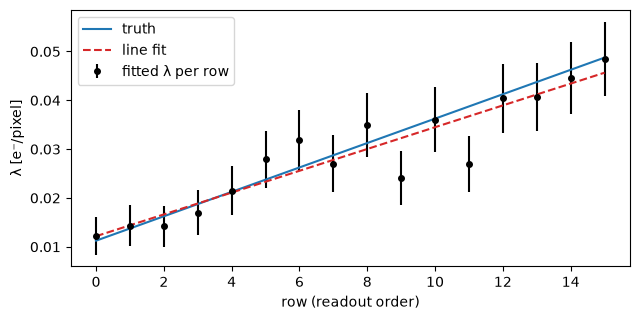

DC  = 0.0179 ± 0.0024  (truth 0.02)
CIC = 0.0111 ± 0.0023  (truth 0.01);  correlation -0.80


In [6]:
import image_rows as ir
rng = np.random.default_rng(0); R, C, g, s, dc, cic = 16, 844, 1.3, 0.25, 0.02, 0.01
xr = (np.arange(R) + .5) / (R / 2); lam = cic + dc * xr
img = np.array([100 + g * rng.poisson(l, C) + s * rng.normal(size=C) for l in lam])
fit = [ir.row_lambda(row, g, s) for row in img]
L, E = np.array([f[0] for f in fit]), np.array([f[1] for f in fit])
line = ir.line_fit(L, E)
plt.figure(figsize=(6.5, 3.3))
plt.errorbar(range(R), L, E, fmt="ko", ms=4, label="fitted λ per row")
plt.plot(range(R), lam, "C0", label="truth")
plt.plot(range(R), line["lambda_cic"] + line["lambda_dark"] * xr, "C3--", label="line fit")
plt.xlabel("row (readout order)"); plt.ylabel("λ [e⁻/pixel]"); plt.legend(); plt.tight_layout(); plt.show()
corr = line["lambda_dark_cic_cov"] / (line["lambda_dark_err"] * line["lambda_cic_err"])
print(f"DC  = {line['lambda_dark']:.4f} ± {line['lambda_dark_err']:.4f}  (truth {dc})")
print(f"CIC = {line['lambda_cic']:.4f} ± {line['lambda_cic_err']:.4f}  (truth {cic});  correlation {corr:.2f}")

**To check on the first real image:** DC should come out positive. If it is negative on every image, FITS row 0 is the *last* row read:
set `[rows] reverse = true` in `configs/processing.toml`.

## 5. Training and testing every model: `lvl1/train_lvl1.py`

One command trains and tests every level-1 model by **packet-grouped cross-validation**:
* the packets are split into 5 folds;
* each fold is predicted by models trained on the other four.

| Model | What it is |
|---|---|
| `trace_physics` | no learning: noise from the trace's Allan curve ÷ the training mean gain (the baseline) |
| `physics` | **A (default)**: trace physics + learned gain and correction, GPs on settings, packet state and own features |
| `physics_joint` | A with λ from the joint dark-current / CIC fit |
| `sets` | E: A with the 10 trace sets combined by a learned set network |
| `ridge`, `trees`, `gp`, `nn` | the first-round models on settings + own trace and reference features |
| `cnn` | 1D CNN on the trace and reference curves |
| `pretrained` | D: CNN pre-trained on every unlabelled trace, then fine-tuned |
| `deep_kernel` | C: GP on the frozen pre-trained encoder's output, no amplifier term |

Here it runs on 100 synthetic packets (400 examples) with `--quick` (short training; the full run takes longer).

In [7]:
TEST = ROOT / "lvl1" / "test_data"
if not (TEST / "model_inputs" / "physics.npz").exists():
    sh([PY, "lvl1/make_test_data.py", "--packets", "100", "--unlabeled", "300", "--out", str(TEST)], tail=3)
RES = DEMO / "lvl1_results_quick"
sh([PY, "lvl1/train_lvl1.py", "--inputs", str(TEST / "model_inputs"), "--quick", "--out", str(RES)])

400 examples from 100 packets, boards [101], 5 folds (grouped by packet)
trace_physics  sigma_e:  35.5 % (rank 0.89, cover 0.62)  lambda:  30.4 % (rank -0.09, cover 0.68)  gain:  31.3 % (rank -0.17, cover 0.75)       0 s
physics        sigma_e:   5.5 % (rank 0.94, cover 0.71)  lambda:   4.9 % (rank 0.99, cover 0.75)  gain:   0.9 % (rank 0.94, cover 0.71)       6 s
physics_joint  sigma_e:   5.5 % (rank 0.94, cover 0.71)  lambda:   4.6 % (rank 0.99, cover 0.74)  gain:   0.9 % (rank 0.94, cover 0.71)      13 s
sets           sigma_e:   5.1 % (rank 0.95, cover 0.89)  lambda:   4.9 % (rank 0.99, cover 0.75)  gain:   0.9 % (rank 0.94, cover 0.71)      46 s
ridge          sigma_e:  11.5 % (rank 0.66, cover 0.69)  lambda:  11.8 % (rank 0.93, cover 0.74)  gain:   0.8 % (rank 0.94, cover 0.67)       0 s
trees          sigma_e:  10.6 % (rank 0.82, cover 0.70)  lambda:  21.6 % (rank 0.69, cover 0.30)  gain:   3.6 % (rank 0.91, cover 0.81)       4 s
gp             sigma_e:   9.9 % (rank 0.80, cover

## 6. Reading the report

For each model and each target the report gives:

| Score | Meaning | Good |
|---|---|---|
| error | typical relative error, RMS of log(predicted/true) | close to the label error |
| bias | mean of log(predicted/true) | ≈ 0 |
| shape | error after removing each amplifier's own mean error | ≈ error or below |
| rank | within each amplifier: is the order of the true values reproduced? | > 0.9 |
| cover 68/95 | fraction of truths within ±1σ / ±1.96σ | 0.68 / 0.95 |
| calibrated | the same after conformal calibration | 0.68 / 0.95 |
| factor | how much to scale the error bars for 68 % | ≈ 1 |
| label error | the labels' own median error | — |

In [8]:
rep = json.loads((RES / "report.json").read_text())
rows = []
for model, r in rep["results"].items():
    if "skipped" in r:
        continue
    for t, s in r["scores"].items():
        rows.append({"model": model, "target": t, "error %": 100 * s["error"], "bias %": 100 * s["bias"], "shape %": 100 * s["shape"],
                     "rank": s["rank"], "cover68": s["coverage68"], "cover95": s["coverage95"],
                     "calibrated68": s["calibrated_coverage68"], "factor": s["factor68"], "label error %": 100 * (s["label_error"] or np.nan)})
table = pd.DataFrame(rows)
for t in ("sigma_e", "lambda", "gain"):
    print(t)
    display(table[table.target == t].drop(columns="target").set_index("model").round(2))

sigma_e


,error %,bias %,shape %,rank,cover68,cover95,calibrated68,factor,label error %
model,,,,,,,,,
trace_physics,35.51,-4.77,6.88,0.89,0.62,0.99,0.69,1.09,1.5
physics,5.54,-0.21,5.53,0.94,0.72,0.92,0.67,0.89,1.5
physics_joint,5.54,-0.21,5.53,0.94,0.72,0.92,0.67,0.89,1.5
sets,5.11,-0.43,5.09,0.95,0.89,0.97,0.68,0.53,1.5
ridge,11.48,-0.58,11.47,0.66,0.69,0.94,0.69,0.99,1.5
trees,10.57,0.38,10.55,0.82,0.70,0.85,0.69,0.91,1.5
gp,9.87,-0.24,9.87,0.80,0.71,0.89,0.68,0.94,1.5
nn,10.82,-1.39,10.73,0.73,0.48,0.76,0.68,1.59,1.5
cnn,8.39,-0.62,8.13,0.85,0.74,0.94,0.68,0.89,1.5


lambda


,error %,bias %,shape %,rank,cover68,cover95,calibrated68,factor,label error %
model,,,,,,,,,
trace_physics,30.41,-0.00,30.41,-0.09,0.68,0.95,0.68,1.00,3.0
physics,4.94,-0.03,4.94,0.99,0.75,0.96,0.68,0.88,3.0
physics_joint,4.60,0.41,4.58,0.99,0.74,0.96,0.68,0.89,3.0
sets,4.94,-0.03,4.94,0.99,0.75,0.96,0.68,0.88,3.0
ridge,11.78,0.00,11.78,0.93,0.74,0.96,0.68,0.89,3.0
trees,21.63,0.65,21.61,0.69,0.30,0.58,0.69,2.51,3.0
gp,4.32,0.06,4.32,0.99,0.62,0.92,0.68,1.10,3.0
nn,12.64,-0.83,12.61,0.92,0.47,0.78,0.68,1.64,3.0
cnn,11.54,0.11,11.45,0.94,0.72,0.94,0.67,0.92,3.0


gain


,error %,bias %,shape %,rank,cover68,cover95,calibrated68,factor,label error %
model,,,,,,,,,
trace_physics,31.28,-0.00,2.53,-0.17,0.75,1.00,0.68,0.71,0.8
physics,0.89,-0.00,0.89,0.94,0.71,0.96,0.67,0.94,0.8
physics_joint,0.89,-0.00,0.89,0.94,0.71,0.96,0.67,0.94,0.8
sets,0.89,-0.00,0.89,0.94,0.71,0.96,0.67,0.94,0.8
ridge,0.84,-0.00,0.84,0.94,0.67,0.96,0.68,1.02,0.8
trees,3.63,0.12,3.61,0.91,0.81,0.92,0.68,0.59,0.8
gp,0.83,-0.00,0.83,0.94,0.66,0.95,0.68,1.04,0.8
nn,1.13,0.04,1.12,0.90,0.73,0.96,0.68,0.91,0.8
cnn,1.40,0.11,1.39,0.86,0.92,0.99,0.68,0.57,0.8


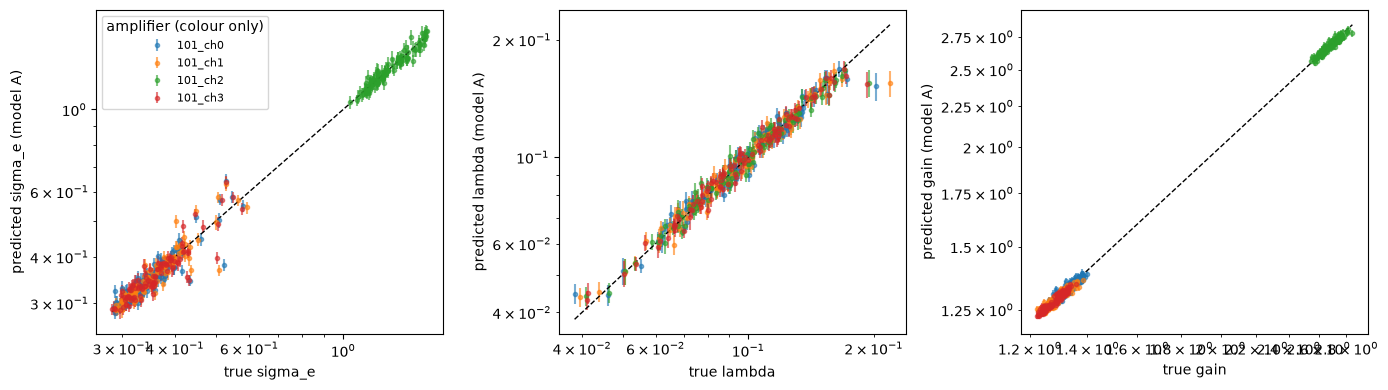

In [9]:
pred = pd.read_csv(RES / "predictions.csv")
amp = pred["board"].astype(str) + "_ch" + pred["channel"].astype(str)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, t in zip(axes, ("sigma_e", "lambda", "gain")):
    for a in sorted(amp.unique()):
        sel = amp == a
        ax.errorbar(np.exp(pred.loc[sel, f"true log {t}"]), np.exp(pred.loc[sel, f"physics: log {t}"]),
                    yerr=np.exp(pred.loc[sel, f"physics: log {t}"]) * pred.loc[sel, f"physics: sd {t}"], fmt="o", ms=3, alpha=0.6, label=a)
    lim = [np.exp(pred[f"true log {t}"]).min(), np.exp(pred[f"true log {t}"]).max()]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(f"true {t}"); ax.set_ylabel(f"predicted {t} (model A)")
axes[0].legend(fontsize=8, title="amplifier (colour only)")
plt.tight_layout(); plt.show()

**What this shows (synthetic packets):**
* **Trace physics alone** is far off in *level*, because without a label the gain is unknown. It still *orders* the settings well within each amplifier.
* **Model A** learns the gain and a small correction. It brings σe, λ and the gain close to the labels' own errors.
* **The models that learn everything** from features or curves need more packets to get there.

The amplifiers sit on different lines because their gains and noise differ. A model given **no amplifier label** still places each example on its own amplifier's line, from that amplifier's traces.

**On real data** the same command runs on `processed/model_inputs`. A suggested level-1 pass mark, to agree on:
* the best label-free model predicts σe on held-out packets within about twice the label error;
* it ranks σe correctly within each amplifier (rank > 0.9);
* its calibrated error bars cover 68 % / 95 %.

## 7. Checklist for the first real packets

* **Manifest:** `make_manual_manifest.py` reports status `ok`; every requested change arrived; `trace_matches_image` is true (same NDCM and binning).
* **WADERs:** labels without flags for the amplifiers used. ch2's gain cannot be measured from a 1×1 image yet, so its labels will usually be flagged.
* **Row order:** `label.lambda_dark` is positive (otherwise set `[rows] reverse = true`).
* **Scale:** at least ~10 packets before the cross-validation scores mean much (5 folds of 2 packets). The physics model is useful from ~15 packets in the synthetic tests.
* **Run** `train_lvl1.py --inputs processed/model_inputs` and compare `trace_physics` with `physics`. The difference is what the image sees that the trace alone does not.